
# 🧠 Decision Tree Workshop

Welcome to the **Decision Tree Workshop**, where you’ll explore the principles of **non-parametric and non-linear models** through hands-on experimentation with **Decision Trees**.

This notebook is part of your **active learning** experience — designed for **peer programming**, **critical reflection**, and **modular code design** using the **Machine Learning Pipeline Pattern**.

---



## 🎯 Learning Objectives

By the end of this workshop, you will:
- Understand how **Decision Trees** work conceptually.
- Apply them to **Regression** (California housing dataset) and **Classification** (Iris dataset).
- Build and structure your code using the **Machine Learning Pipeline Pattern**.
- Visualize and interpret model behavior.
- Reflect on model interpretability, performance, and MLOps tracking.
---



## 🧭 Workshop Flow

### **Before the Workshop**
1. Review the lecture slides on *non-parametric models*.
2. Read the `DecisionTreeRegressor` and `DecisionTreeClassifier` documentation.
3. Form groups of 2–3 students for peer programming.
4. Fork and clone the workshop repository.

### **During the Workshop**
- Perform EDA and data preprocessing.
- Build regression and classification models.
- Visualize decision structures and feature importances.
- Implement a modular ML pipeline.
- Collaborate and review peer code.

### **After the Workshop**
- Summarize your reflections on the algorithm.
- Push your code and report to GitHub.
- Peer review another group’s notebook.
---



## 🌳 Understanding Decision Trees

Decision Trees split data recursively into smaller subsets based on feature thresholds that **maximize information gain** (for classification) or **minimize variance** (for regression).

### **Key Concepts**
- **Non-parametric:** No assumption about data distribution.
- **Non-linear:** Can model complex relationships.
- **Interpretability:** Each branch is a human-readable rule.
- **Overfitting Risk:** Deep trees may capture noise.

### **Tree Learning Process**
1. Choose the best split based on impurity (e.g., Gini, entropy, or MSE).
2. Recursively split until stopping criteria are met.
3. Use majority vote (classification) or mean (regression) for predictions.

### Want to deepen your understanding of **Decision Tree Algorithm**?

Check out this short video lesson:
👉 [Watch on YouTube: Decision and Classification Trees](https://youtu.be/_L39rN6gz7Y?si=N6SI0DWPfhZJDMGB)


---



## 📦 Step 1: Data Loading and Exploration

We will use two datasets from `scikit-learn`:
- **California Housing dataset** → Regression
- **Iris dataset** → Classification


In [8]:

# === STUDENT CODE SECTION ===
# 👉 TASK: Load the datasets and perform basic exploration

from sklearn.datasets import fetch_california_housing, load_iris
import pandas as pd

# Load datasets
california = fetch_california_housing(as_frame=True)
iris = load_iris(as_frame=True)

# Convert to DataFrames
california_df = california.frame
iris_df = iris.frame

# Display first few rows
california_df.head(), iris_df.head()

# 💡 HINT: Use .describe(), .info(), and .value_counts() for further exploration


(   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
 0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
 1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
 2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
 3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
 4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   
 
    Longitude  MedHouseVal  
 0    -122.23        4.526  
 1    -122.22        3.585  
 2    -122.24        3.521  
 3    -122.25        3.413  
 4    -122.25        3.422  ,
    sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
 0                5.1               3.5                1.4               0.2   
 1                4.9               3.0                1.4               0.2   
 2                4.7               3.2                1.3               0.2   
 3                4.6               3.1  


## 🧹 Step 2: Data Preprocessing

Prepare your data for training:
- Handle missing values
- Split into train/test sets
- Standardize features if necessary


In [9]:

# === STUDENT CODE SECTION ===
# 👉 TASK: Preprocess data (train/test split, optional scaling)

from sklearn.model_selection import train_test_split

# Split datasets
X_california = california_df.drop('MedHouseVal', axis=1)
y_california = california_df['MedHouseVal']

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_california, y_california, test_size=0.2, random_state=42)

X_iris = iris_df.drop('target', axis=1)
y_iris = iris_df['target']

X_train_i, X_test_i, y_train_i, y_test_i = train_test_split(X_iris, y_iris, test_size=0.2, random_state=42)

# 💡 HINT: Use StandardScaler if you plan to normalize features.



## 🤖 Step 3: Train Decision Tree Models

We’ll train:
1. A **DecisionTreeRegressor** for the California housing dataset.
2. A **DecisionTreeClassifier** for the Iris dataset.


In [10]:

# === STUDENT CODE SECTION ===
# 👉 TASK: Train both models

from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier

# Regression model
reg_tree = DecisionTreeRegressor(max_depth=6, random_state=42)
reg_tree.fit(X_train_c, y_train_c)

# Classification model
clf_tree = DecisionTreeClassifier(max_depth=4, random_state=42)
clf_tree.fit(X_train_i, y_train_i)

# 💡 HINT: Try adjusting max_depth and observe overfitting.


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at 


## 📊 Step 4: Evaluate Models


In [11]:

# === STUDENT CODE SECTION ===
# 👉 TASK: Evaluate regression (MSE, R²) and classification (accuracy, confusion matrix)

from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, confusion_matrix

# Regression evaluation
y_pred_c = reg_tree.predict(X_test_c)
print("Regression MSE:", mean_squared_error(y_test_c, y_pred_c))
print("Regression R2:", r2_score(y_test_c, y_pred_c))

# Classification evaluation
y_pred_i = clf_tree.predict(X_test_i)
print("Classification Accuracy:", accuracy_score(y_test_i, y_pred_i))
print("Confusion Matrix:\n", confusion_matrix(y_test_i, y_pred_i))


Regression MSE: 0.4972838079675652
Regression R2: 0.6205125146233951
Classification Accuracy: 1.0
Confusion Matrix:
 [[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]



## 🌈 Step 5: Visualize Decision Trees and Feature Importances


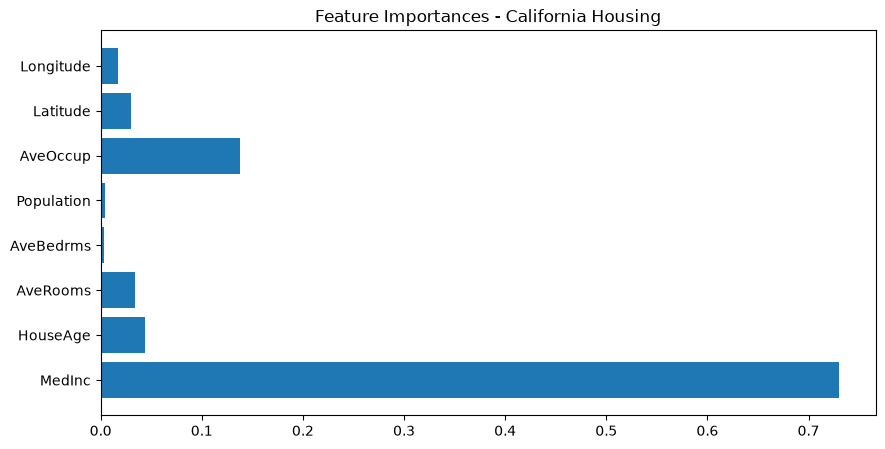

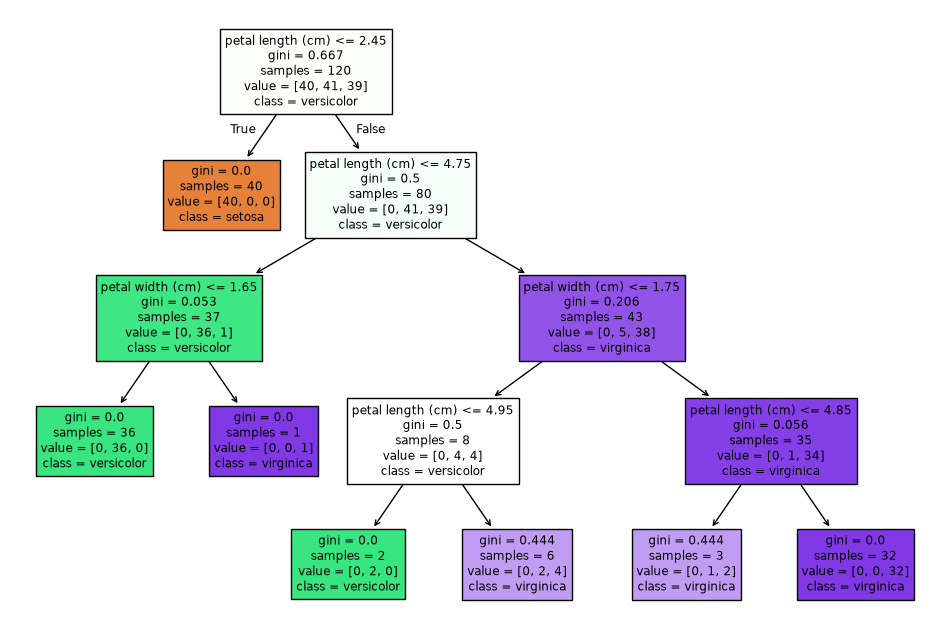

In [12]:

# === STUDENT CODE SECTION ===
# 👉 TASK: Visualize feature importances and tree structure

from sklearn import tree
import matplotlib.pyplot as plt

# Feature importances
plt.figure(figsize=(10,5))
plt.barh(X_california.columns, reg_tree.feature_importances_)
plt.title("Feature Importances - California Housing")
plt.show()

# Tree visualization
plt.figure(figsize=(12,8))
tree.plot_tree(clf_tree, filled=True, feature_names=iris.feature_names, class_names=iris.target_names)
plt.show()

# 💡 HINT: Try exporting tree as DOT file with tree.export_graphviz()



## ⚙️ Step 6: MLOps Extension — Model Tracking (Placeholder)

Model tracking helps manage experiments, log metrics, and version models.  
Here, we simulate how you might integrate a tracking system such as **MLflow**.


In [13]:

# === STUDENT CODE SECTION ===
# 👉 TASK: Placeholder for MLOps tracking setup

# 💡 HINT: This is a simulation. You can later replace it with real MLflow tracking.

experiment_name = "DecisionTree_Experiment"
params = {"max_depth": 6, "criterion": "squared_error"}
metrics = {"mse": mean_squared_error(y_test_c, y_pred_c), "r2": r2_score(y_test_c, y_pred_c)}

print(f"Experiment: {experiment_name}")
print("Parameters:", params)
print("Metrics:", metrics)

# 💡 HINT: In MLflow, you’d use mlflow.log_params() and mlflow.log_metrics()


Experiment: DecisionTree_Experiment
Parameters: {'max_depth': 6, 'criterion': 'squared_error'}
Metrics: {'mse': 0.4972838079675652, 'r2': 0.6205125146233951}


## 🧩 Step 7: Understand How the Algorithm Works (Essential)

To build intuition and become a more effective machine learning practitioner, it is important to understand **how the algorithm works behind the scenes**, not just how to run it.

Read the **coaching notebook**, which takes you behind the scenes to explore:

- How splitting decisions are made

- How prediction errors are calculated
- How the tree is constructed step by step
- How hyperparameters influence model behavior
- How to interpret results and troubleshoot models

### 🎯 Challenges

Complete the five challenges in the **coaching notebook** (notebooks folder) and record your answers below.

**Challenge 1:**  
The total SSE at threshold 7.0 is 44. The left group has an SSE of 0, and the right group has an SSE of 44. A decision tree compares different splits and chooses the one with the lowest error. In this example, 7.0 is actually the best split because it gives the lowest SSE out of the possible thresholds.

**Challenge 2:**  
When I changed min_samples_leaf from 1 to 2, the split at hour 18 disappeared because it would create a leaf with only one observation. The tree instead split at hour 13.5. The prediction for hour 21 changed from 8 to 12. This is not a bug. It is a restriction that helps the model avoid overfitting.

**Challenge 3:**  
From the results, depth 6 performed the best on the test data because it had the lowest test MSE of 0.284. Depth 1 was too simple and had high errors. When I removed the depth limit, the training error became 0, but the test error increased to 0.336. This suggests overfitting. I would investigate depth 6 further using cross-validation to check whether its performance is consistent.

**Challenge 4:**  
Depth 1 gave 80% training accuracy, while depth 4 gave 85%. The deeper tree learned more patterns and made one more correct prediction. However, it also became more complex. A simpler tree is easier to understand, while a deeper tree might overfit the training data. We would need to test on new data to know which one is actually better.

**Challenge 5:**  
In the housing dataset, a leaf predicts a numerical house value based on the average target value of houses that reach that leaf. In the Iris dataset, a leaf predicts a flower species based on the most common class in that group. So regression predicts a number, while classification predicts a category.

### 🚪 Exit Ticket

After completing the challenges, answer the exit ticket question(s) below.

1. A regression tree chooses a split by finding the threshold that produces the lowest prediction error.



2. A regression leaf predicts the average target value of the observations in that leaf when using squared-error loss.



3. A classification tree usually measures node purity using Gini impurity or entropy.



4. Increasing maximum depth can help the model learn more patterns, but it can also cause overfitting.


## 🧩 Step 8: Reflection and Discussion

Reflect on:
1. What are the strengths and weaknesses of Decision Trees?
2. When are Decision Trees preferable to linear models?
3. How does model depth affect bias and variance?
4. What challenges arise when integrating models into MLOps pipelines?

Write your answers below.


1. Decision Trees are easy to understand and visualize because they make predictions using simple conditions. They can handle complex and non-linear relationships, and they usually do not need feature scaling. However, one major weakness is overfitting. If the tree becomes too deep, it may memorize the training data and perform poorly on new data.

2. Decision Trees are better when the relationship between variables is not a straight line. For example, electricity prices change depending on the time of day. A Decision Tree can learn these different price ranges using conditions, while a simple linear model may not capture these sudden changes properly.

3. A shallow tree usually has high bias because it is too simple and may miss important patterns. This is called underfitting. A deeper tree can learn more details and reduce bias, but it can also have high variance because it becomes sensitive to the training data. This can cause overfitting. So we need to choose a depth that balances both.

4. Some challenges include tracking different versions of the model, keeping records of datasets and parameters, and making sure results can be reproduced. We also need to monitor the model after deployment to check whether its performance changes over time. Tools like MLflow can help us manage experiments and track model performance.



## 🚀 Step 9: Publish Your Work to GitHub and Collaborate as a Team

Professional data scientists and machine learning engineers use **Git** and **GitHub** to manage code, track changes, and collaborate with others. In this final step, you will prepare your work for submission and publish it to a shared repository.

### ✅ Before You Push

Make sure you have completed all of the following:

1. Run **all cells** in both notebooks from beginning to end.
2. Verify that all outputs, visualizations, and model results are displayed correctly.
3. Complete **Section 7** in `DecisionTreeRegression_Workshop.ipynb`.
4. Complete **Section 8** in `DecisionTreeRegression_Workshop.ipynb`.
5. Save the notebook, along with any other Python scripts or Jupyter notebooks (if any).

### 📂 Create Your Repository

Each team must create a GitHub repository named exactly:

```text
DecisionTreeRegression_Workshop
```

### 👥 Team Collaboration Requirements

This is a **group assignment**.

- The repository must contain contributions from **all team members**.
- Each team member should commit and push their own work.
- Use meaningful commit messages to document contributions.
- Ensure the final repository contains the completed notebooks and any supporting files required to run the workshop.

### 📤 Push Your Work to GitHub

After completing the workshop:

1. Initialize Git in your project folder (if needed).
2. Commit your changes.
3. Connect your local project to the GitHub repository.
4. Push your work to GitHub.
5. Verify that all files appear correctly in the remote repository.

### 🐙 GitHub Submission Checklist

- [ ] Both notebooks run without errors.
- [ ] Sections 7 and 8 are complete.
- [ ] Repository name is `DecisionTreeRegression_Workshop`.
- [ ] All team members have contributed.
- [ ] Latest changes have been pushed to GitHub.
- [ ] Repository is ready for instructor review.

### 💡 Reflection

Briefly describe your team's workflow and collaboration process.

*Write your answer here.*